### **3.2 Data preparation**

In this unit we download the churn dataset, read it with pandas and prepare it for machine learning: make the column names and values uniform, fix the column that pandas read incorrectly, and translate the target variable to numbers.

First, the imports:

In [658]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

**Downloading and reading the data**

The dataset is hosted on GitHub:

In [659]:
df = pd.read_csv("https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The dataframe has 21 columns: customerid, gender, seniorcitizen, partner, dependents, tenure, phoneservice, multiplelines, internetservice, onlinesecurity, onlinebackup, deviceprotection, techsupport, streamingtv, streamingmovies, contract, paperlessbilling, paymentmethod, monthlycharges, totalcharges and churn. With this many columns, df.head() hides some of them behind ... in the middle. To see all of them at once we can transpose the dataframe - flip rows and columns - with df.head().T. The output is long, so we show only some of the rows:

In [660]:
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


**Making everything uniform**

The column names are inconsistent: some start with an uppercase letter (CustomerID, Tenure), some contain spaces (Monthly Charges is MonthlyCharges here, but the values inside columns do contain spaces). The values are also inconsistent - we see No, Yes, No phone service and so on. We lowercase everything and replace spaces with underscores:

In [661]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [662]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [663]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [664]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
# we put .index as we are not interested in the values of the df.dtypes ('str', 'int64' etc) but the actual index
# we create a list with the index

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(" ", "_")

In [665]:
df.head(6)

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes
5,9305-cdskc,female,0,no,no,8,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month-to-month,yes,electronic_check,99.65,820.5,yes


In [666]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


<Axes: >

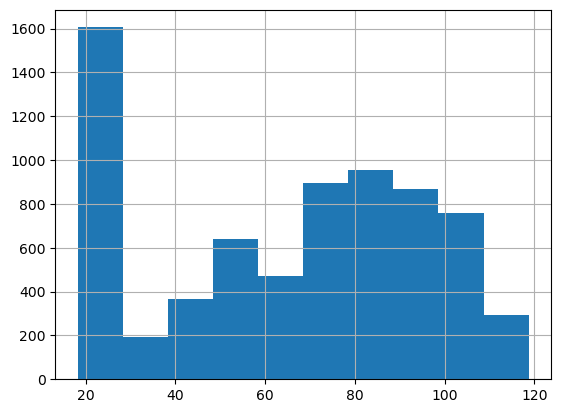

In [667]:
df["monthlycharges"].hist()

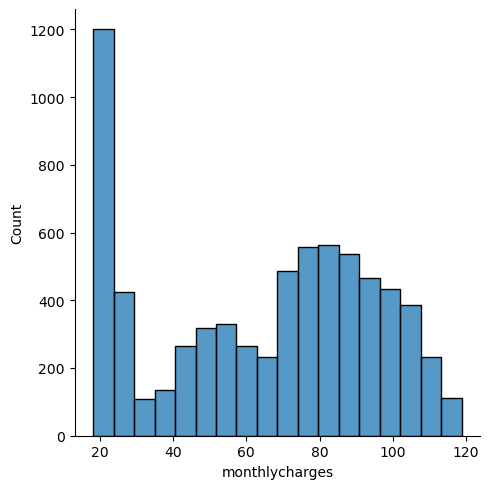

In [668]:
sns.displot(data=df, x="monthlycharges")

<Axes: xlabel='monthlycharges', ylabel='Count'>

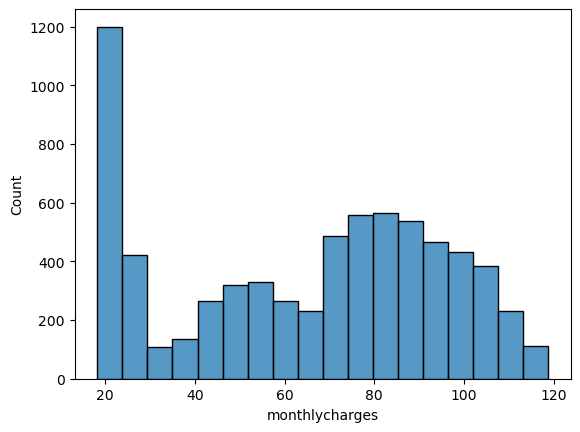

In [669]:
sns.histplot(data=df, x="monthlycharges")

In [670]:
df["monthlycharges"].unique()

array([29.85, 56.95, 53.85, ..., 63.1 , 44.2 , 78.7 ], shape=(1585,))

In [671]:
df.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [672]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [673]:
df.head(5)

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes


In [674]:
df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors='coerce')

In [675]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                   str
dtype: object

In [676]:
df.totalcharges = df.totalcharges.fillna(0)

Zero is not always the best replacement, but in this case it is acceptable: it matches the fact that these customers haven't paid anything yet.

**Encoding the target variable**

The target, churn, still contains strings:

In [677]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: str

For classification we need numbers. We compare the column with 'yes'

this produces a boolean series - and cast it to integers:

In [678]:
df.churn = (df.churn == 'yes').astype(int)

In [679]:
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

Now churn is 1 for customers who churned and 0 for those who stayed. The data is ready for the next step: splitting it into train, validation and test sets.



**Notes**

This session covered data obtention and some procedures of data preparation.

Commands, functions, and methods:

- !wget - Linux shell command for downloading data
- pd.read.csv() - read csv files
- df.head() - take a look of the dataframe
- df.head().T - take a look of the transposed dataframe
- df.columns - retrieve column names of a dataframe
- df.columns.str.lower() - lowercase all the letters in the columns names of a dataframe
- df.columns.str.replace(' ', '_') - replace the space separator in the columns names of a dataframe
- df.dtypes - retrieve data types of all series
- df.index - retrieve indices of a dataframe
- pd.to_numeric() - convert a series values to numerical values. The errors='coerce' argument allows making the transformation despite some encountered errors.
- df.fillna() - replace NAs with some value
- (df.x == "yes").astype(int) - convert x series of yes-no values to numerical values.

### **3.3 - Setting Up The Validation Framework**

In [680]:
from sklearn.model_selection import train_test_split

We want the classic 60/20/20 split: 60% of the data for training, 20% for validation and 20% for testing. The function only splits in two, so we do it in two steps.

In [681]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
# we put df_full_train instead of df_train so that later we can return to it to do some EDA

In [682]:
len(df_full_train), len(df_test)

(5634, 1409)

In [683]:
#Now let us create the actual validation
#If we want a validation dataset to represent 20% of full dataset --> 25% of df_full_train (0.2/0.8)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [684]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [685]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


In [686]:
#Let us retrieve the target variable
y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test= df_test['churn'].values

In [687]:
df_train.shape, df_val.shape, df_test.shape

((4225, 21), (1409, 21), (1409, 21))

In [688]:
y_train.shape,  y_val.shape, y_train.shape

((4225,), (1409,), (4225,))

In [689]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [690]:
df.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

**Notes**
Splitting the dataset with Scikit-Learn.

Classes, functions, and methods:

- train_test_split - Scikit-Learn class for splitting a dataset into two parts. The test_size argument states how large the test set should be. The random_state argument sets a random seed for reproducibility purposes.
- df.reset_index(drop=True) - reset the indices of a dataframe and delete the previous ones.
- df.x.values - extract the values from x series
- del df['x'] - delete x series from a dataframe

### **3.4 - EDA**

Now we explore the training data: we check for missing values, look at the distribution of the target variable, and go through the numerical and categorical columns. For EDA we use the full train set - train and validation together - because we will also use it to compute feature importance later.

First we reset its index, as we did for the other parts:

In [691]:
df_full_train = df_full_train.reset_index(drop =True)

**Missing values**

The check is simple - for every column we count the NaN values:

In [692]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

**Looking at the target: the churn rate**

Next we look at the target variable - how many customers churned and how many stayed:

In [693]:
df_full_train.churn.value_counts(normalize=True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

About 73% of the customers stayed and 27% churned. The percentage of ones - 0.269968, roughly 27% - is called the churn rate.

Because churn is now a column of ones and zeros, there is a shortcut for computing it: the mean. The mean of a binary column is the number of ones divided by the total number of rows, which is exactly the churn rate:

In [694]:
df_full_train.churn.mean()

np.float64(0.26996805111821087)

Same number. This works for any binary variable: its mean is always the fraction of ones.

**Numerical and categorical variables**

Next we decide which columns are numerical and which are categorical. Most columns in this dataset contain strings, so they are categorical. Among the numeric ones, seniorcitizen is really a categorical variable - it is just encoded as 0/1 - and churn is the target. That leaves three numerical variables:

In [695]:
df_full_train.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                 int64
dtype: object

In [696]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

And 16 categorical ones - everything except customerid (an identifier, useless as a feature), the three numerical variables and the target:

In [697]:
categorical = df_full_train.dtypes

In [698]:
categorical = list(df_full_train.dtypes[df_full_train.dtypes == 'str'].index) 
categorical

['customerid',
 'gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod']

In [699]:
categorical.append("seniorcitizen")
categorical

['customerid',
 'gender',
 'partner',
 'dependents',
 'phoneservice',
 'multiplelines',
 'internetservice',
 'onlinesecurity',
 'onlinebackup',
 'deviceprotection',
 'techsupport',
 'streamingtv',
 'streamingmovies',
 'contract',
 'paperlessbilling',
 'paymentmethod',
 'seniorcitizen']

In [700]:
df_full_train[categorical].nunique()

customerid          5634
gender                 2
partner                2
dependents             2
phoneservice           2
multiplelines          3
internetservice        3
onlinesecurity         3
onlinebackup           3
deviceprotection       3
techsupport            3
streamingtv            3
streamingmovies        3
contract               3
paperlessbilling       2
paymentmethod          4
seniorcitizen          2
dtype: int64

In [701]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]
#We removed customer id

Most variables have two or three values; paymentmethod has four - it is the most diverse one. The number of categories matters later: it determines how many columns we get after one-hot encoding.


### Notes
The EDA for this project consisted of:

- Checking missing values
- Looking at the distribution of the target variable (churn)
- Looking at numerical and categorical variables

Functions and methods:

- df.isnull().sum() - returns the number of null values in the dataframe.
- df.x.value_counts() returns the number of values for each category in x series. The normalize=True argument retrieves the percentage of each category. In this project, the mean of churn is equal to the churn rate obtained with the value_counts method.
round(x, y) - round an x number with y decimal places
- df[x].nunique() - returns the number of unique values in x series

### **3.5 - Feature Importance: Churn Rate And Risk Ratio**

Feature importance analysis is a part of EDA: we want to identify which features affect our target variable. In this unit we do it for categorical variables by comparing the churn rate of each group with the global churn rate, first as a difference and then as a ratio.

**Churn rate per group**

The reference point is the global churn rate - the churn rate we computed in the EDA unit:

In [702]:
global_churn = df_full_train.churn.mean()
global_churn 

np.float64(0.26996805111821087)

Now we look at individual variables. Let's start with gender:

In [703]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()

The global churn rate is 0.27, women churn at 0.2768 and men at 0.2632. The differences are tiny.
 
We compute them explicitly as the global rate minus the group rate:

In [704]:
global_churn - churn_female

np.float64(-0.006855983216553063)

In [705]:
global_churn - churn_male

np.float64(0.006754520462819769)

Both differences are close to zero, so gender is probably not an important feature: knowing whether a customer is a man or a woman tells us almost nothing about churn.


Now let's look at a more promising variable - whether the customer has a partner. First, how many customers are there in each group?


In [706]:
df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

Then the churn rates:

In [707]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()

This looks very different from gender. Customers with a partner churn at 20.5%, customers without one at 33% - and the global rate is 27%. So single customers are much more likely to churn. The differences from the global rate:

In [708]:
global_churn - churn_partner 

np.float64(0.06493474245795922)

In [709]:
global_churn - churn_no_partner 

np.float64(-0.05984095297455855)

With this definition - global rate minus group rate - a positive difference means the group churns less than average, and a negative difference means it churns more. The larger the absolute difference, the more important the variable.

**Risk ratio**

The difference is expressed in absolute terms. The same idea can be expressed in relative terms - as a ratio between the group churn rate and the global churn rate:

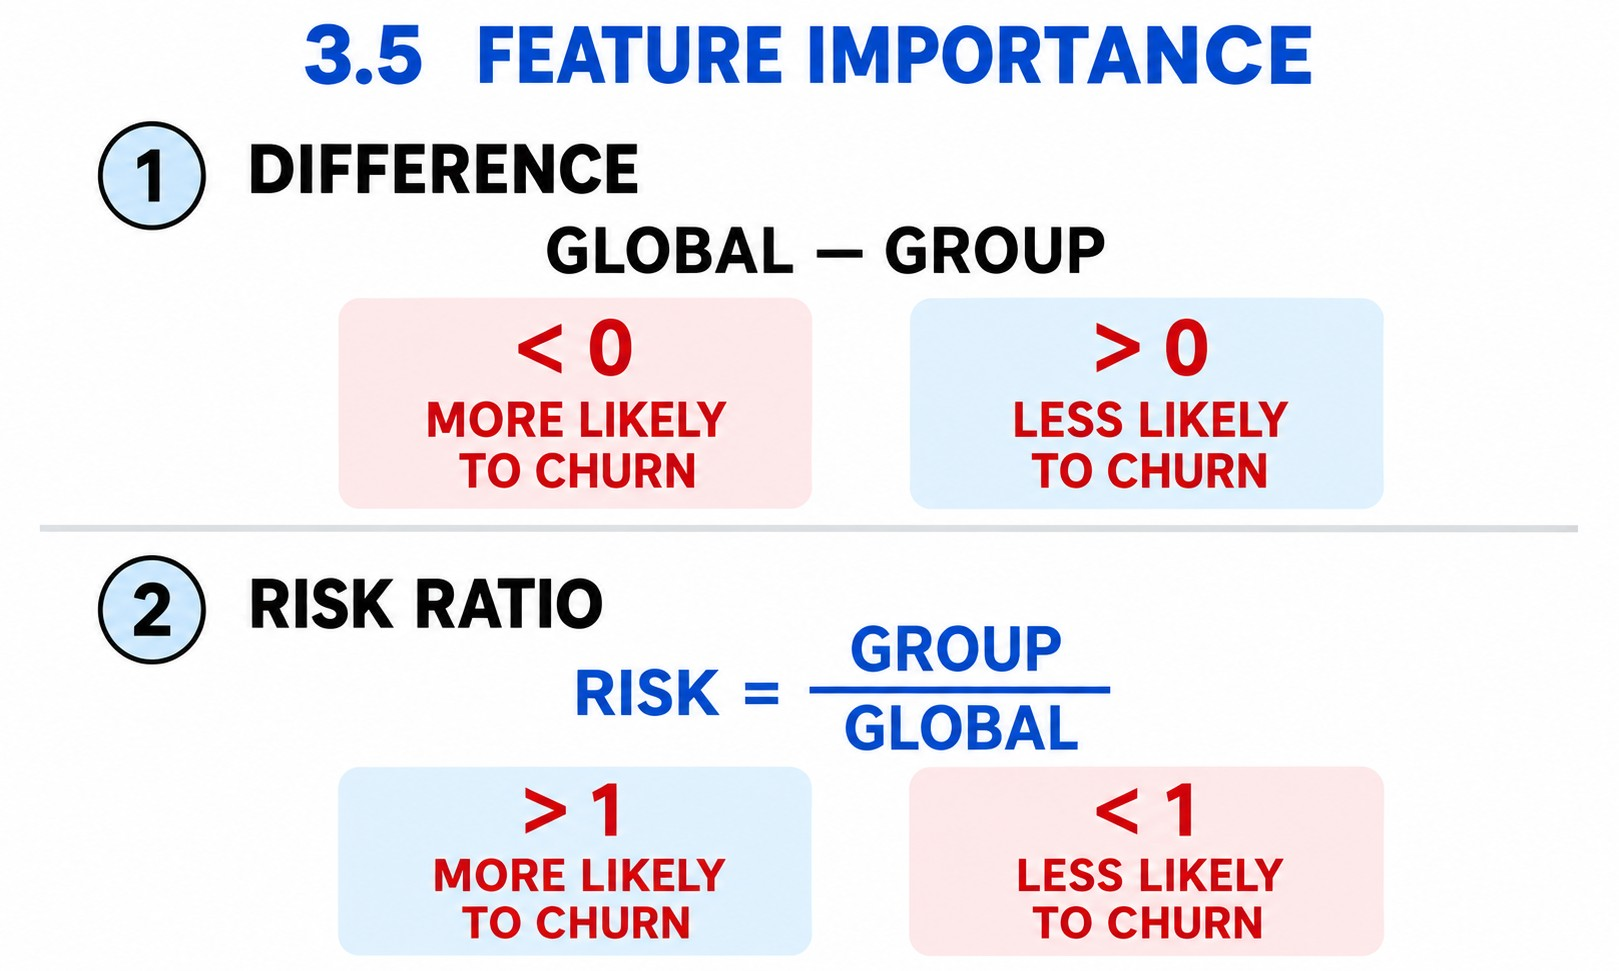

In [710]:
churn_no_partner / global_churn

np.float64(1.2216593879412643)

In [711]:
churn_partner / global_churn

np.float64(0.7594724924338315)

This is the risk ratio. It is easy to read:

risk = 1 means the group is as likely to churn as everyone else

risk > 1 means the group is more likely to churn

risk < 1 means the group is less likely to churn

Customers without a partner have a risk of 1.22 - they churn 22% more often than the average customer. Customers with a partner have a risk of 0.76 - they churn about 24% less often.

**Doing it for every variable with groupby**

Doing this manually for every variable is tedious. The operation we did is expressible as a SQL query:

SELECT
    gender,
    AVG(churn),
    AVG(churn) - global_churn AS diff,
    AVG(churn) / global_churn AS risk
FROM
    data
GROUP BY
    gender;

In pandas the same thing is a groupby with an aggregation:

In [712]:
from IPython.display import display

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472




dependents


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043792,1.162212
yes,0.165666,1666,-0.104302,0.613651




phoneservice


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028652,0.893870
yes,0.273049,5087,0.003081,1.011412




multiplelines


,mean,count,diff,risk
multiplelines,,,,
no,0.257407,2700,-0.012561,0.953474
no_phone_service,0.241316,547,-0.028652,0.893870
yes,0.290742,2387,0.020773,1.076948




internetservice


,mean,count,diff,risk
internetservice,,,,
dsl,0.192347,1934,-0.077621,0.712482
fiber_optic,0.425171,2479,0.155203,1.574895
no,0.077805,1221,-0.192163,0.288201




onlinesecurity


,mean,count,diff,risk
onlinesecurity,,,,
no,0.420921,2801,0.150953,1.559152
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.153226,1612,-0.116742,0.567570




onlinebackup


,mean,count,diff,risk
onlinebackup,,,,
no,0.404323,2498,0.134355,1.497672
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.217232,1915,-0.052736,0.804660




deviceprotection


,mean,count,diff,risk
deviceprotection,,,,
no,0.395875,2473,0.125907,1.466379
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.230412,1940,-0.039556,0.853480




techsupport


,mean,count,diff,risk
techsupport,,,,
no,0.418914,2781,0.148946,1.551717
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.159926,1632,-0.110042,0.592390




streamingtv


,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072864,1.269897
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.302723,2167,0.032755,1.121328




streamingmovies


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068938,1.255358
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.307273,2200,0.037305,1.138182




contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


Scanning through all 16 tables, some variables stand out. For contract, customers on a month-to-month contract churn far more than average, while two-year contracts almost never churn:

internetservice tells a similar story - fiber optic customers churn much more than DSL customers:

And in paymentmethod, customers paying by electronic check are the riskiest group in this table:

So contract type, internet service and payment method look important; gender and phone service do not. What these per-group tables cannot do is compare the importance of whole variables with each other - for that we need mutual information, which is the next unit.

**Notes***
Churn rate: Difference between global mean of the target variable and mean of the target variable for categories of a feature. If this difference is greater than 0, it means that the category is less likely to churn, and if the difference is lower than 0, the group is more likely to churn. The larger differences are indicators that a variable is more important than others.

Risk ratio: Ratio between mean of the target variable for categories of a feature and global mean of the target variable. If this ratio is greater than 1, the category is more likely to churn, and if the ratio is lower than 1, the category is less likely to churn. It expresses the feature importance in relative terms.

Functions and methods:

df.groupby('x').y.agg([mean()]) - returns a dataframe with mean of y series grouped by x series
display(x) displays an output in the cell of a jupyter notebook.

### **3.6 - Feature Importance: Mutual Information**

In [713]:
from sklearn.metrics import mutual_info_score

Let's measure it for a few variables. 

For contract:

In [714]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

For gender:

In [715]:
mutual_info_score(df_full_train.gender, df_full_train.churn)


0.0001174846211139946

And for partner:


In [716]:
mutual_info_score(df_full_train.partner, df_full_train.churn)

0.009967689095399745

The order of the arguments doesn't matter - mutual information is symmetric, so mutual_info_score(df_full_train.contract, df_full_train.churn) gives the same 0.0983.


The numbers confirm what we saw with the risk ratios. Contract has by far the highest score: knowing the contract type teaches us a lot about churn. Gender is almost 0: knowing the gender tells us practically nothing. Partner sits in between.



**Applying it to all categorical variables**

We could repeat this manually for all 16 variables, but there is a shorter way. mutual_info_score takes two arguments, while pandas apply passes one series at a time - so we wrap it in a function of one argument:

In [717]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [718]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

The result puts everything on one scale. Contract is the most important categorical variable, followed by onlinesecurity and techsupport - customers without these services churn more, as we saw in the risk ratio tables. At the bottom of the list we find multiplelines, phoneservice and gender - variables that tell us almost nothing about churn.

This covers the categorical variables. For numerical ones we need a different measure - correlation, which is the next unit.

**Notes**
Mutual information is a concept from information theory, which measures how much we can learn about one variable if we know the value of another. In this project, we can think of this as how much do we learn about churn if we have the information from a particular feature. So, it is a measure of the importance of a categorical variable.

Classes, functions, and methods:

mutual_info_score(x, y) - Scikit-Learn class for calculating the mutual information between the x target variable and y feature.

- df[x].apply(y) - apply a y function to the x series of the df dataframe.
- df.sort_values(ascending=False).to_frame(name='x') - sort values in an ascending order and called the column as x.

### **3.7 - Feature Importance: Correlation**

Mutual information measures the importance of categorical variables. 

For numerical variables we use the correlation coefficient instead: it tells us how strongly each numerical feature is related to churn.

**The correlation coefficient**

The correlation coefficient - the Pearson correlation coefficient, usually denoted r - measures the degree of dependency between two variables. It is always a number between -1 and 1:

- A value close to 1 means strong positive correlation: when one variable grows, the other grows too.
- A value close to -1 means strong negative correlation: when one variable grows, the other decreases.
- A value close to 0 means there is no dependency: a change in one variable tells us nothing about the other.

The sign gives the direction of the relationship, and the absolute value gives its strength. One way to interpret the magnitude:

- LOW when the absolute value of r is between 0 and 0.2
- MEDIUM when it is between 0.2 and 0.5
- STRONG when it is between 0.5 and 1.0

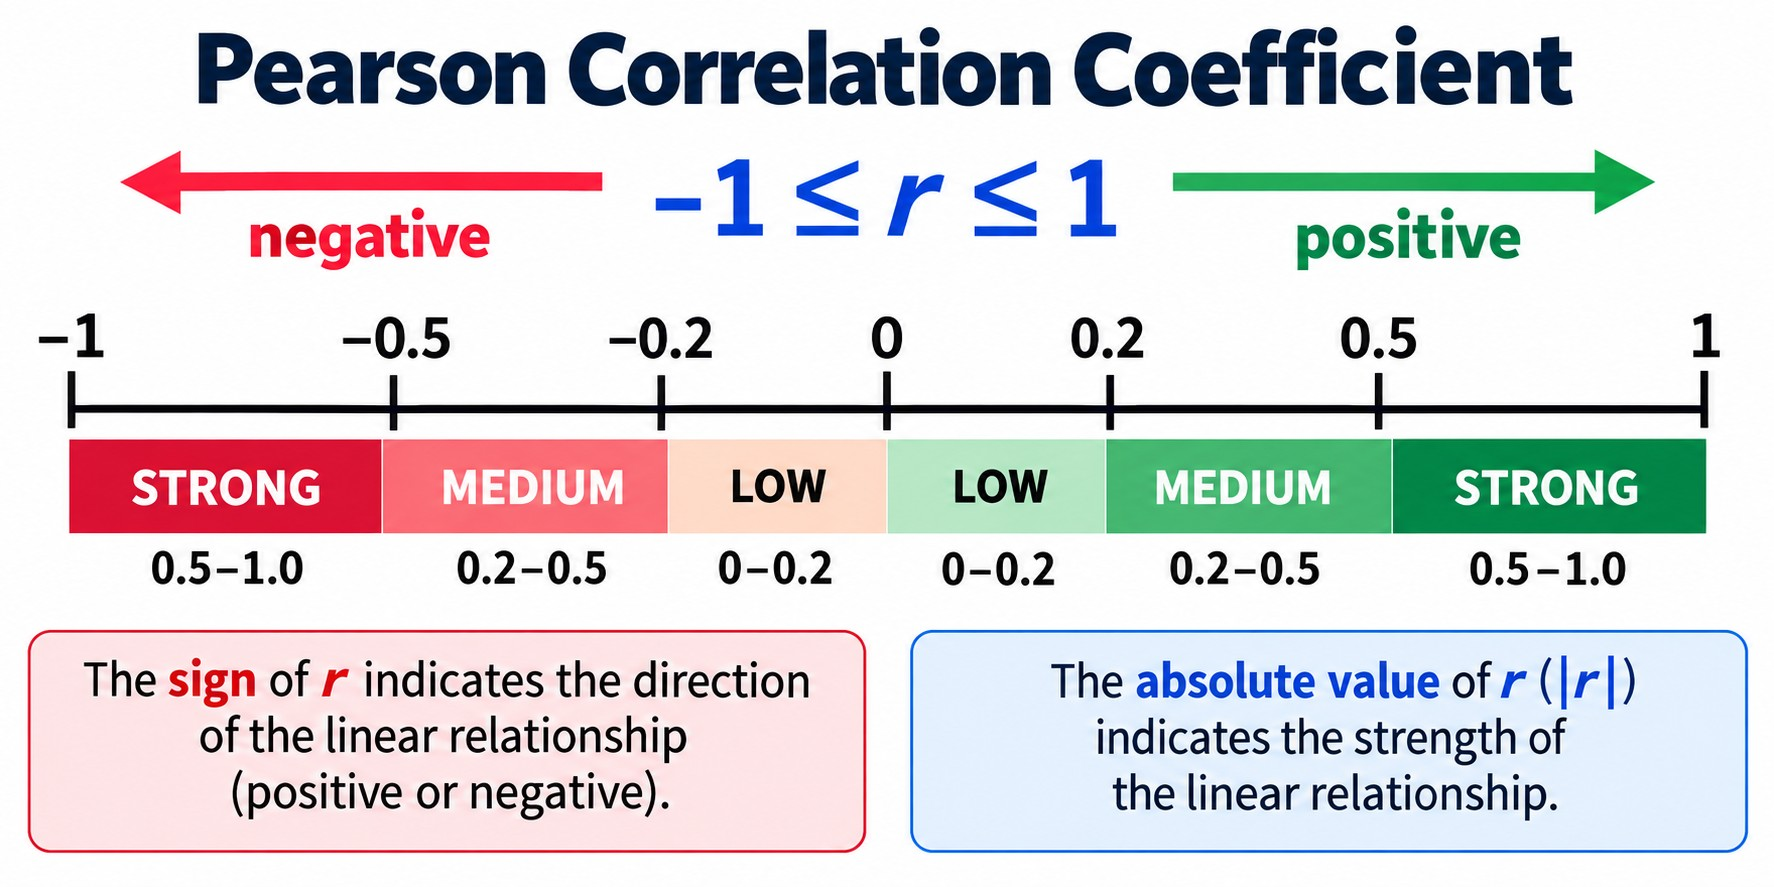

In our case one of the two variables is churn - a binary 0/1 column. If the correlation between a numerical feature and churn is positive, customers with higher values of that feature churn more; if it is negative, they churn less. The larger the absolute value, the more important the feature.

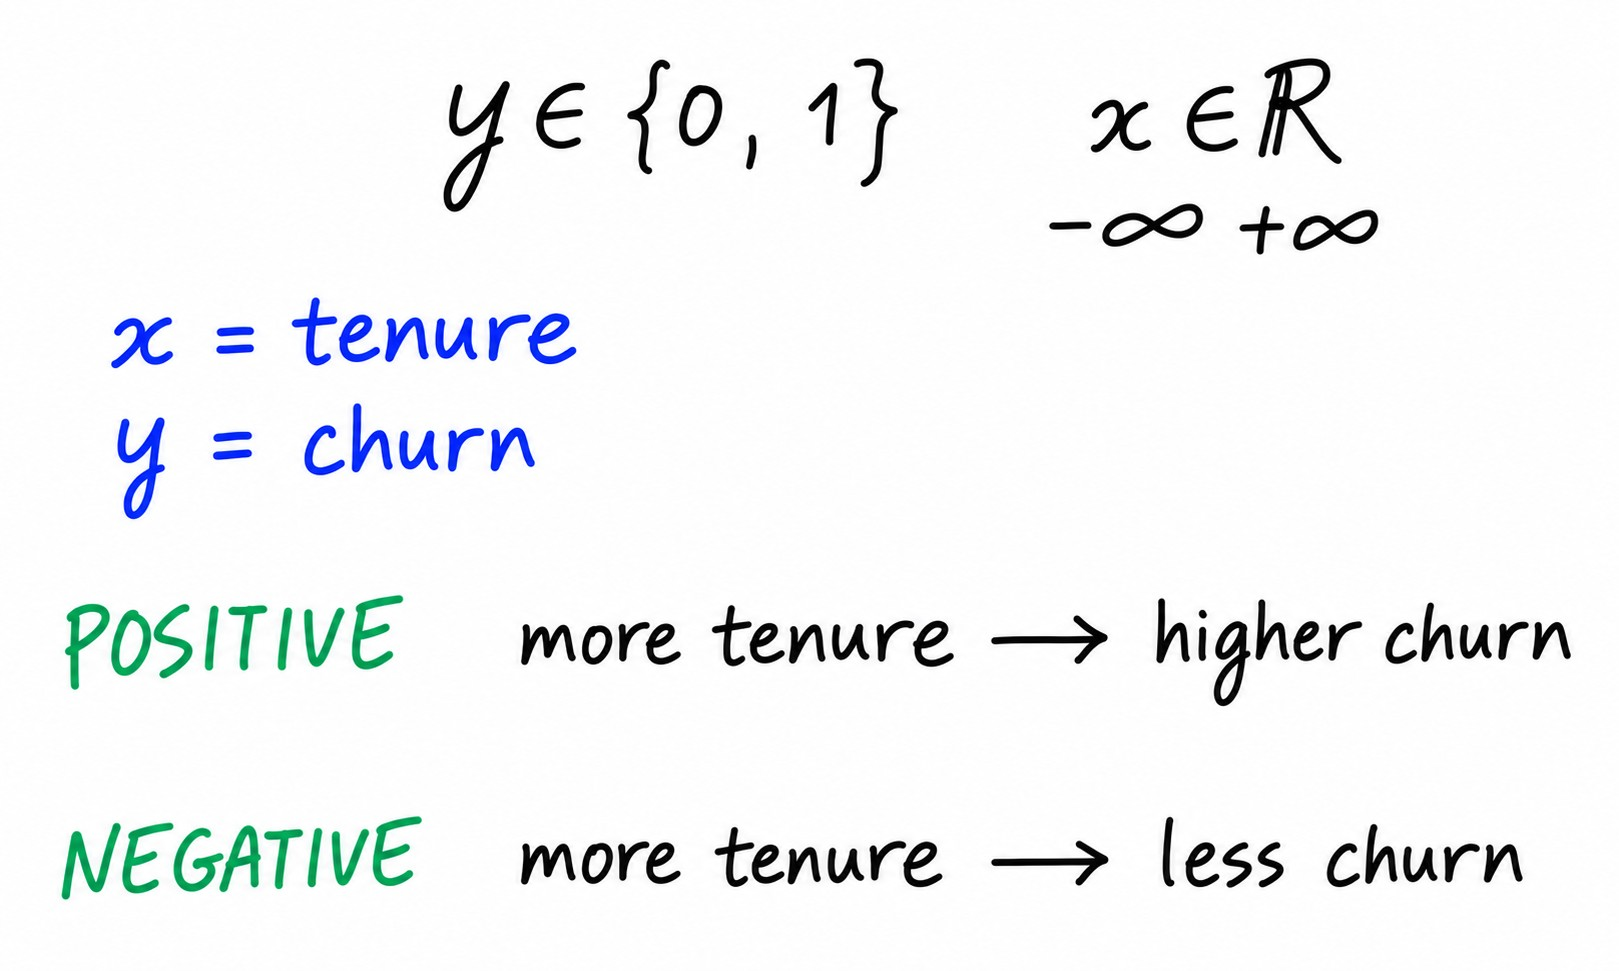

**Correlation of numerical features with churn**

We have three numerical variables: tenure, monthlycharges and totalcharges. Pandas computes their correlation with the target in one call with corrwith:

In [719]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

Let's read this:

Tenure has a medium negative correlation. The longer customers stay with the company, the less likely they are to churn.
Monthly charges have a low-to-medium positive correlation: the more customers pay per month, the more likely they are to churn.

Total charges have a low-to-medium negative correlation - not surprising, since total charges accumulate with tenure.
To rank features by importance we don't care about the direction, only about the strength, so we take the absolute values:

In [720]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

Tenure is the most important numerical feature.

**Checking the relationship with groups**

We can double-check the correlation by splitting customers into groups and computing the churn rate in each - the same idea we used for categorical variables, now applied to bins of a numerical one.

Tenure is measured in months and goes up to 72:

In [721]:
df_full_train.tenure.max()

np.int64(72)

We split it into three groups - two months or less, up to a year, and longer than a year - and look at the churn rate in each:

In [722]:
df_full_train[df_full_train.tenure <= 2].churn.mean()

np.float64(0.5953420669577875)

In [723]:
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()

np.float64(0.3994413407821229)

In [724]:
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

The pattern is striking. Customers who have been with the company for two months or less churn at almost 60%. For customers of up to a year it is about 40%, and for those who stayed longer than a year only about 18%. Churn clearly decreases as tenure grows - exactly what the negative correlation told us.

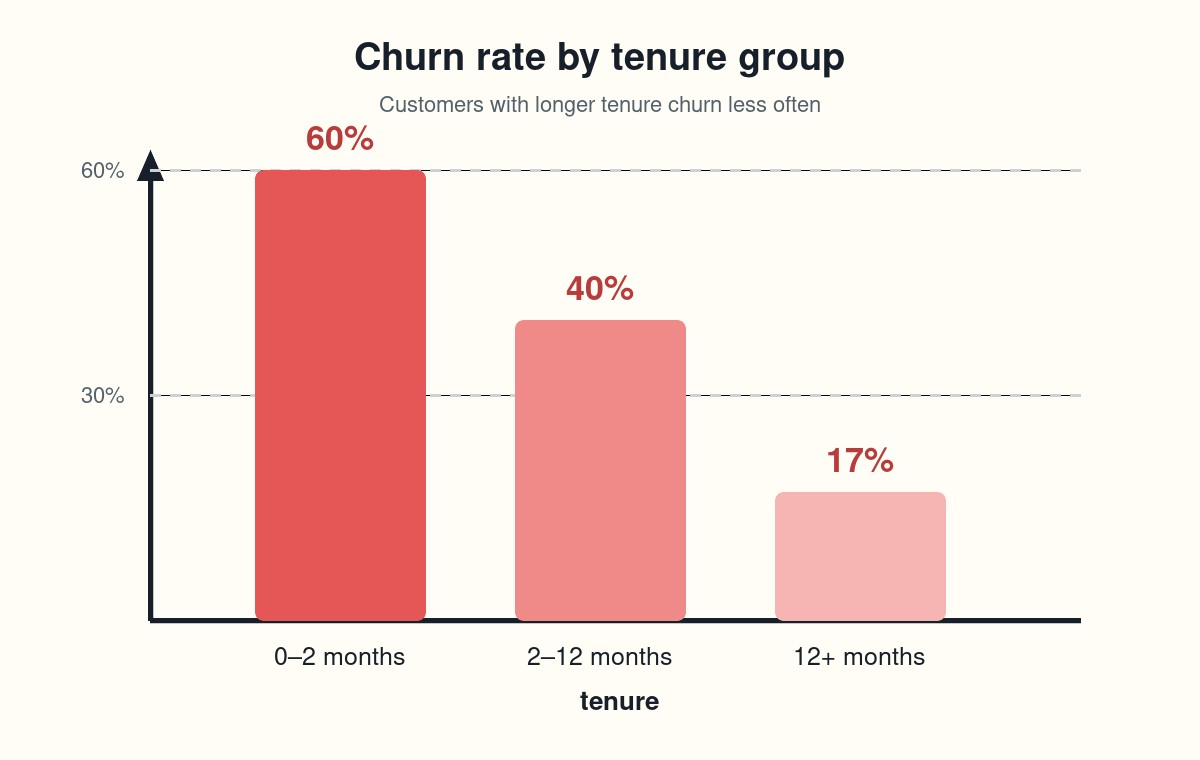

The same check for monthly charges:

In [725]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

np.float64(0.08795411089866156)

In [726]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

np.float64(0.18340943683409436)

In [727]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()

np.float64(0.32499341585462205)

Here the relationship goes the other way: customers paying at most $20 churn at about 9%, and customers paying more than $50 churn at about 32%. The more people pay monthly, the more likely they are to leave - the positive correlation confirmed.

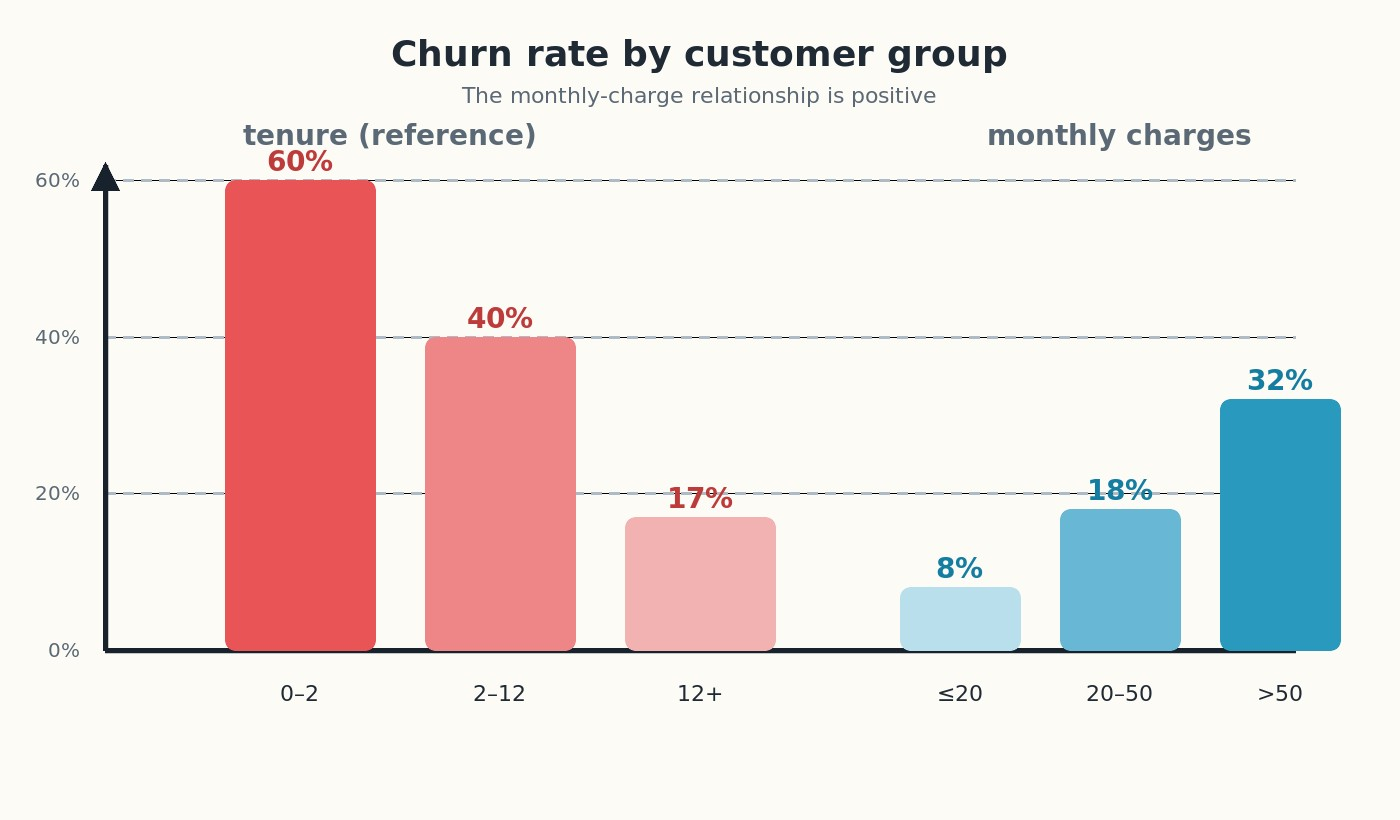

We now know the importance of categorical variables (mutual information) and numerical variables (correlation). Next we prepare the categorical variables for the model with one-hot encoding.

**Notes**

Correlation coefficient measures the degree of dependency between two variables. This value is negative if one variable grows while the other decreases, and it is positive if both variables increase. Depending on its size, the dependency between both variables could be low, moderate, or strong. It allows measuring the importance of numerical variables.

If r is correlation coefficient, then the correlation between two variables is:

- LOW when r is between [0, -0.2) or [0, 0.2)
- MEDIUM when r is between [-0.2, -0.5) or [0.2, 0.5)
- STRONG when r is between [-0.5, -1.0] or [0.5, 1.0]

Positive Correlation vs. Negative Correlation

- When r is positive, an increase in x will increase y.
- When r is negative, an increase in x will decrease y.
- When r is 0, a change in x does not affect y.

Functions and methods:

df[x].corrwith(y) - returns the correlation between x and y series. This is a function from pandas.

### **3.8 - One-Hot Encoding**

In this lesson we encode categorical features as numbers, so they can be used by a machine learning model. The technique is called one-hot encoding, and Scikit-Learn gives us a convenient way to do it with DictVectorizer.

**Why we need encoding**

So far we looked at categorical variables one at a time: churn rate per contract type, risk ratio per payment method, mutual information. That told us which features are useful. Now we want to put all the features together into one matrix and train a model on it.

Machine learning models work with numbers. Our numerical variables - tenure, monthlycharges, totalcharges - are already numbers. But contract contains strings like two_year, and paymentmethod contains strings like electronic_check. We cannot multiply a string by a weight, so we need to translate these values into numbers first.

**One-hot encoding**

One-hot encoding replaces one categorical column with several binary columns - one per category. Each new column says whether the row has that category (1) or not (0).

For example, in our dataset contract has three possible values: month-to-month, one_year and two_year. One row of the dataset

{"contract": "two_year", "tenure": 72, "monthlycharges": 115.5}

becomes

contract=month-to-month  contract=one_year  contract=two_year  tenure  monthlycharges


                      0                  0                  1      72           115.5

Only one of the contract columns is "hot" (set to 1) - that is where the name one-hot encoding comes from.


The same transformation can be shown directly as a table. Each categorical value becomes a binary column, and exactly one column is 1 within each feature group:

![Capture d’écran 2026-10-11 à 11.43.42.png](<attachment:Capture d’écran 2026-10-11 à 11.43.42.png>)
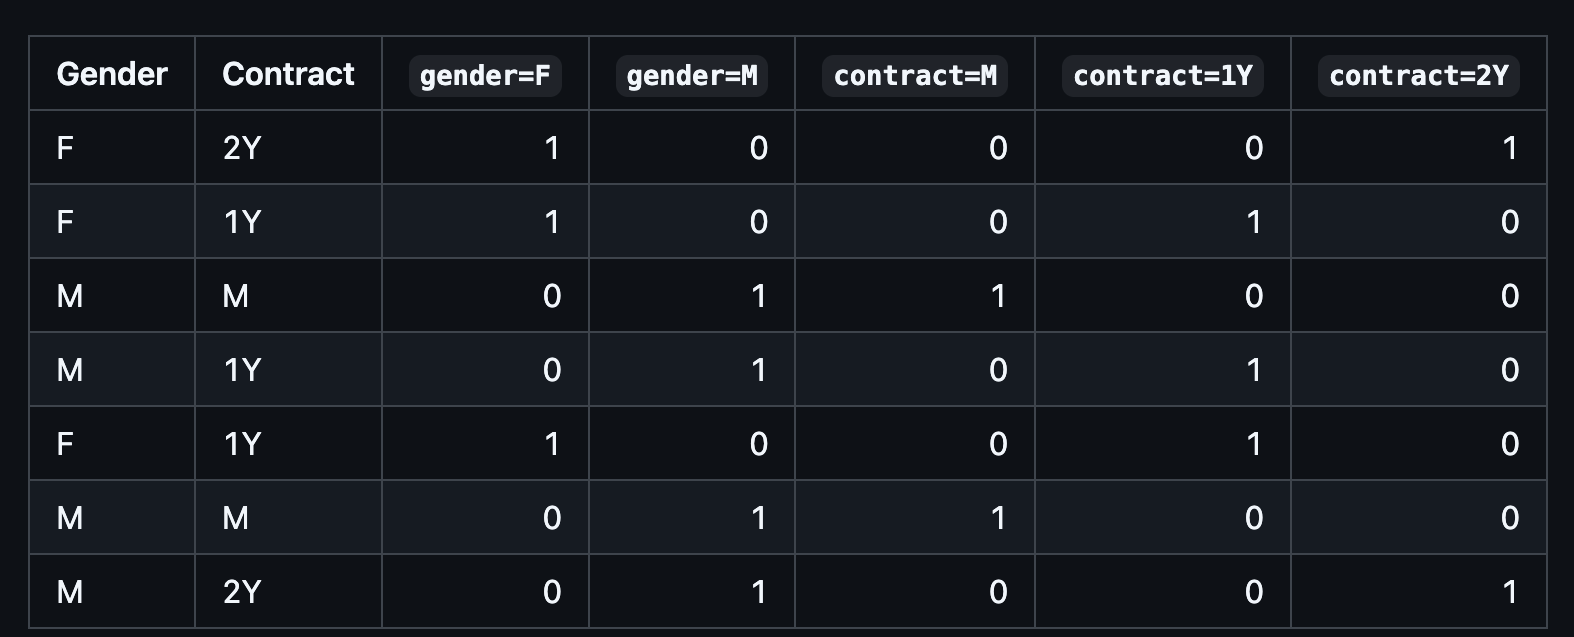

We do this for every categorical feature. The paymentmethod feature has four values, so it becomes four columns. gender has two values, so it becomes two columns. The numerical features pass through unchanged - we keep them as they are.

**Turning rows into dictionaries**

DictVectorizer takes a list of dictionaries, one dictionary per row. We convert a dataframe to this format with pandas:

In [728]:
dicts = df[categorical + numerical].to_dict(orient='records')

In [729]:
dicts

[{'gender': 'female',
  'seniorcitizen': 0,
  'partner': 'yes',
  'dependents': 'no',
  'phoneservice': 'no',
  'multiplelines': 'no_phone_service',
  'internetservice': 'dsl',
  'onlinesecurity': 'no',
  'onlinebackup': 'yes',
  'deviceprotection': 'no',
  'techsupport': 'no',
  'streamingtv': 'no',
  'streamingmovies': 'no',
  'contract': 'month-to-month',
  'paperlessbilling': 'yes',
  'paymentmethod': 'electronic_check',
  'tenure': 1,
  'monthlycharges': 29.85,
  'totalcharges': 29.85},
 {'gender': 'male',
  'seniorcitizen': 0,
  'partner': 'no',
  'dependents': 'no',
  'phoneservice': 'yes',
  'multiplelines': 'no',
  'internetservice': 'dsl',
  'onlinesecurity': 'yes',
  'onlinebackup': 'no',
  'deviceprotection': 'yes',
  'techsupport': 'no',
  'streamingtv': 'no',
  'streamingmovies': 'no',
  'contract': 'one_year',
  'paperlessbilling': 'no',
  'paymentmethod': 'mailed_check',
  'tenure': 34,
  'monthlycharges': 56.95,
  'totalcharges': 1889.5},
 {'gender': 'male',
  'seniorc

The orient='records' argument means "one dictionary per row".

**DictVectorizer**

DictVectorizer lives in sklearn.feature_extraction:

In [730]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

Like every Scikit-Learn transformer, it has a fit step and a transform step:

- fit learns the list of categories for each column
- transform turns dictionaries into a matrix

fit_transform does both in one call. With sparse=False the result is a usual NumPy array. By default DictVectorizer returns a sparse matrix - a data structure that stores only the non-zero elements, because most of the matrix is zeros. Sparse matrices are more memory efficient, but for this dataset it is simpler to work with a dense array.

To see what columns the vectorizer created, use dv.get_feature_names_out(). For the full dataset we get 45 names: one column per category value (contract=month-to-month, internetservice=fiber_optic, ...) plus the three numerical columns. The resulting matrix has 45 columns, one per feature name:

In [731]:
X_train.shape

(4225, 45)

4225 is the number of rows in the training set, 45 is the number of features after encoding.

**Encoding the validation set**

The validation set must be encoded in exactly the same way as the training set. That is why we call fit only on the training data - for the validation data we reuse the already fitted vectorizer and call only transform:

In [732]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

If we called fit again on validation, the columns could come out in a different order - or a category that appears only in validation would create a new column. The matrix would no longer match the one the model was trained on.

In [733]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

**Alternative: OneHotEncoder**

Scikit-Learn also has a dedicated OneHotEncoder class that works on dataframes directly instead of dictionaries. We show how to combine it with feature scaling in the second notebook for this module (notebook-scaling-ohe.ipynb).



**Notes**

One-Hot Encoding allows encoding categorical variables in numerical ones. This method represents each category of a variable as one column, and a 1 is assigned if the value belongs to the category or 0 otherwise.

Classes, functions, and methods:

- df[x].to_dict(orient='records') - convert x series to dictionaries, oriented by rows.
- DictVectorizer().fit_transform(x) - Scikit-Learn class for one-hot encoding by converting x dictionaries into a sparse matrix. It does not affect the numerical variables.
- DictVectorizer().get_feature_names() - return the names of the columns in the sparse matrix.

### **3.9 - Logistic Regression**

In this lesson we look at logistic regression - the model we will use for churn prediction. We see how it relates to linear regression from the previous module, implement the sigmoid function, and write the model in code.

Binary classification
Our problem - predicting churn - is a binary classification problem: the target variable takes one of two values. We encoded it as 1 for customers who churned (the positive class) and 0 for customers who stayed (the negative class). Spam detection is another example: 1 for spam, 0 for not spam.

A supervised model is a function that maps features to the target:


![Capture d’écran 2026-10-11 à 12.22.10.png](<attachment:Capture d’écran 2026-10-11 à 12.22.10.png>)
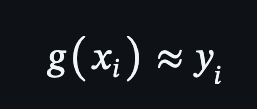

For classification, the output of g is a number between 0 and 1: the probability that xi belongs to the positive class. If the model outputs 0.8 for a customer, we say it believes there is an 80% chance this customer will churn.



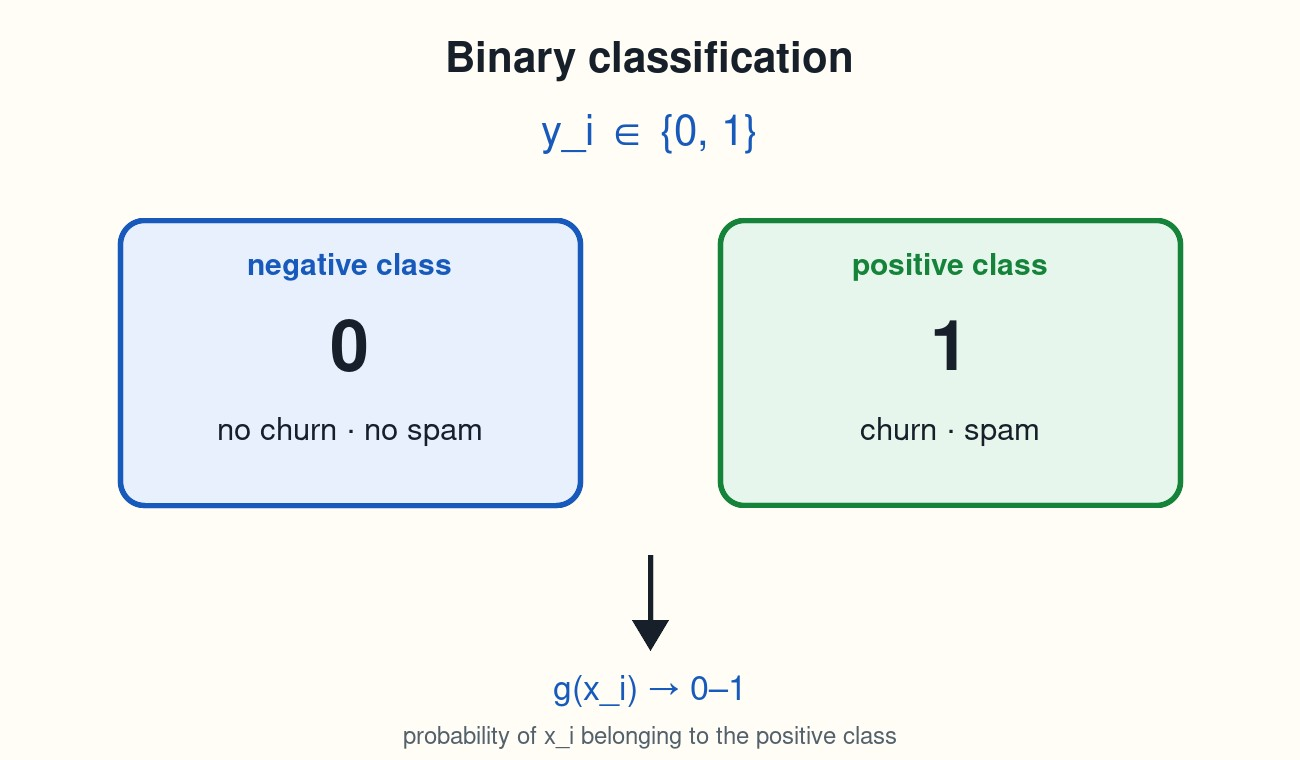

**From linear regression to logistic regression**

In the previous module we used linear regression, which computes a weighted sum of the features:

![Capture d’écran 2026-10-11 à 12.29.11.png](<attachment:Capture d’écran 2026-10-11 à 12.29.11.png>)
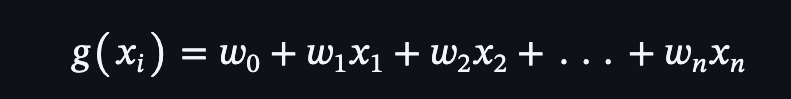

Here w0 is the bias term (what we predict when all features are zero) and w1 ... wn are the weights - each one says how much its feature contributes to the prediction. The output can be any real number, which is fine for predicting a price, but a probability must stay between 0 and 1.

Logistic regression is the same linear model with one extra step: we apply the sigmoid function to the weighted sum:

![Capture d’écran 2026-10-11 à 12.29.38.png](<attachment:Capture d’écran 2026-10-11 à 12.29.38.png>)
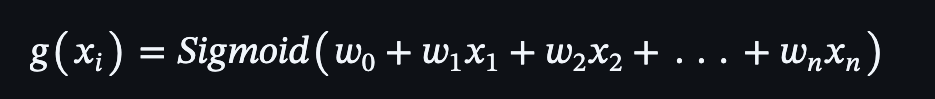

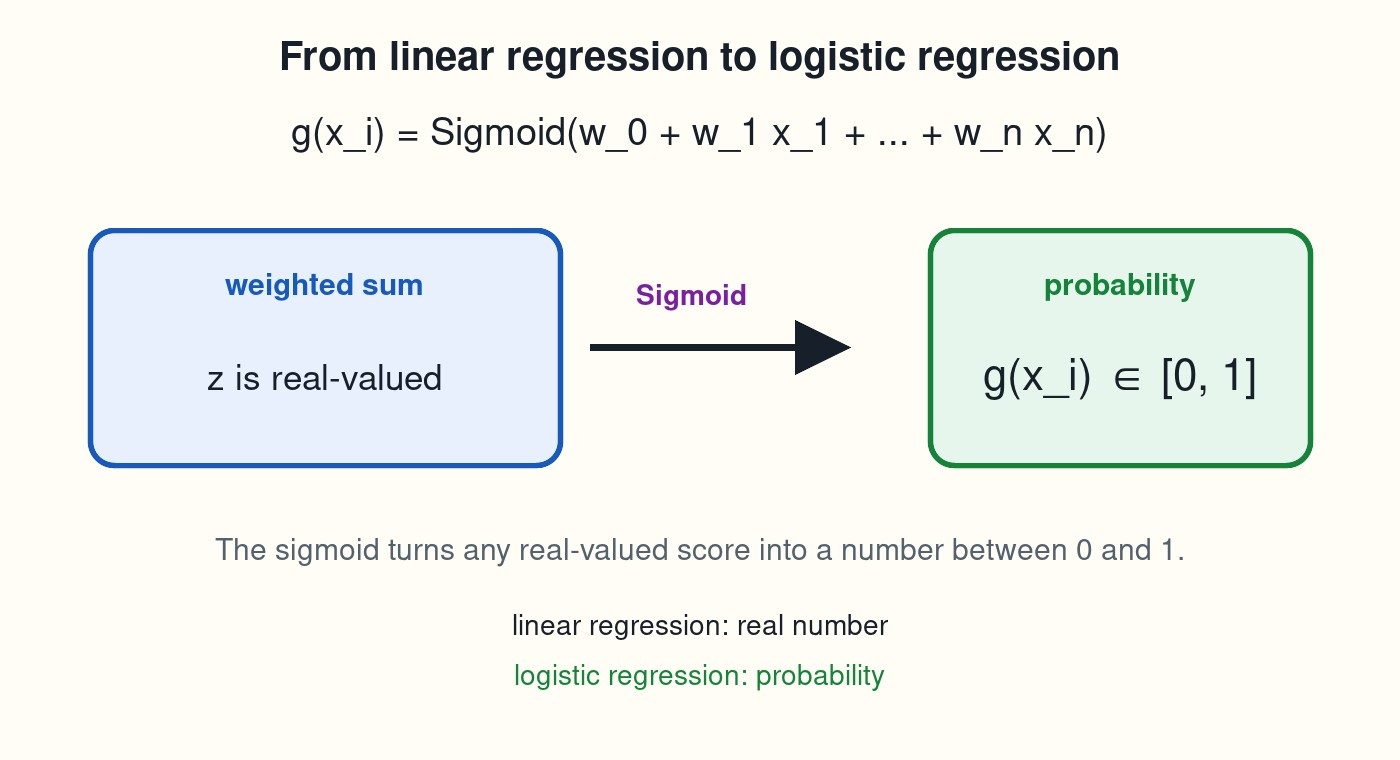

![Capture d’écran 2026-10-11 à 12.31.37.png](<attachment:Capture d’écran 2026-10-11 à 12.31.37.png>)
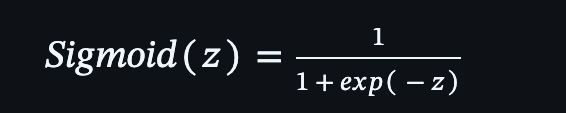

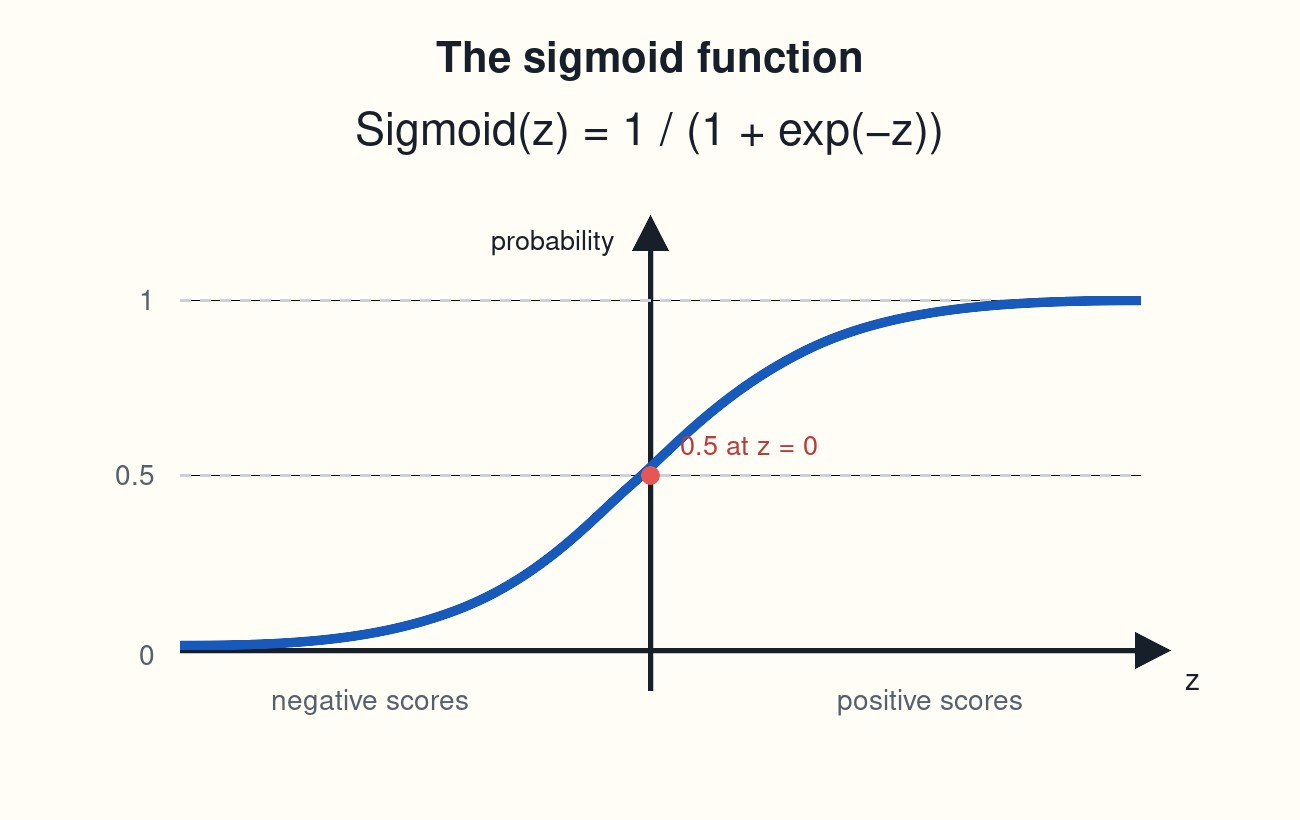

The sigmoid squashes any real number into the range between 0 and 1. That turns the raw score into a probability. Both models are called linear models, because the score inside is still a linear combination of the features - only the final transformation differs.

**The sigmoid function**

In NumPy:

In [734]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

A few sanity checks show the properties of the function:

In [735]:
sigmoid(10000)

np.float64(1.0)

A large positive score maps to 1.0. A large negative score maps to 0, and at exactly 0 the sigmoid gives 0.5 - a coin flip. To see the shape, we evaluate the sigmoid on values from -7 to 7 and plot it:

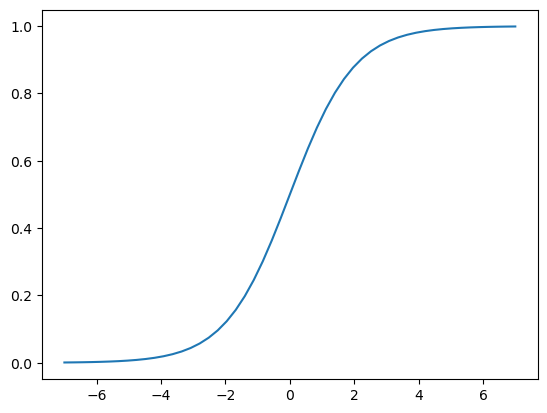

In [736]:
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

The curve has an S shape: scores below roughly -5 give a probability close to 0, scores above roughly 5 give a probability close to 1, and everything in between moves smoothly between the two extremes. A score of 0 means a 50% chance.



**Implementing the models**

Here is linear regression from the previous module, written out with a loop:

In [737]:
def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

Logistic regression needs only one change - pass the score through the sigmoid before returning it:

In [738]:
def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

The two functions are almost identical. That is the whole idea of this lesson: logistic regression is linear regression with a sigmoid on top, which makes the output interpretable as a probability.

In the next lesson we stop implementing things by hand and train this model with Scikit-Learn.

Notes
In general, supervised models can be represented with this formula:

![Capture d’écran 2026-10-11 à 12.38.42.png](<attachment:Capture d’écran 2026-10-11 à 12.38.42.png>)

Depending on what is the type of target variable, the supervised task can be regression or classification (binary or multiclass). Binary classification tasks can have negative (0) or positive (1) target values. The output of these models is the probability of xi belonging to the positive class.



Logistic regression is similar to linear regression because both models take into account the bias term and weighted sum of features. The difference between these models is that the output of linear regression is a real number, while logistic regression outputs a value between zero and one, applying the sigmoid function to the linear regression formula.

![Capture d’écran 2026-10-11 à 12.38.57.png](<attachment:Capture d’écran 2026-10-11 à 12.38.57.png>)


In this way, the sigmoid function allows transforming a score into a probability.
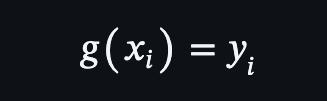
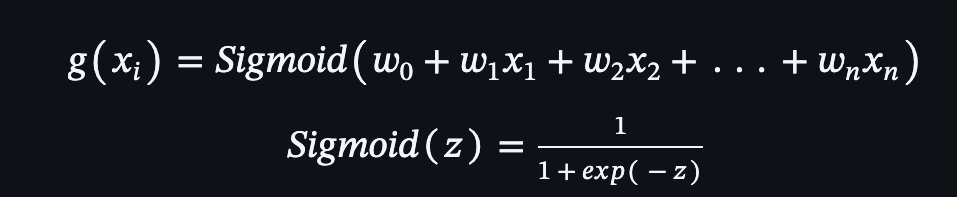

### **3.10 - Training Logistic Regression with Scikit-Learn**

In [739]:
X_train.shape, y_train.shape

((4225, 45), (4225,))

In [740]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs', max_iter=2000, random_state=1)
# solver='lbfgs' is the default solver in newer version of sklearn
# for older versions, you need to specify it explicitly
model.fit(X_train, y_train)

/opt/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

The solver is the optimization algorithm that finds the best weights. After fit, the model has learned both parts of the formula from the previous lesson. The bias term w0 is in intercept_:

In [741]:
print("Bias (intercept):", model.intercept_[0].round(3))

Bias (intercept): -0.059


In [742]:
print("Coefficients:", model.coef_[0].round(3))

Coefficients: [ 0.66   0.011 -0.657  0.043 -0.029  0.104 -0.149  0.059  0.026 -0.012
 -0.474  0.637 -0.149 -0.014 -0.198  0.077  0.135  0.107 -0.149  0.056
  0.275 -0.149 -0.112 -0.177  0.191 -0.057  0.071 -0.059 -0.008  0.101
 -0.019  0.077 -0.063  0.194 -0.096 -0.149  0.259 -0.056 -0.149  0.219
  0.226 -0.149 -0.063 -0.068  0.   ]


In [743]:
len(model.coef_[0].round(3))

45

In [744]:
model.predict(X_train)  # Those are hard predictions as they show the hard labels "churn" or "no churn"

array([0, 1, 1, ..., 1, 0, 1], shape=(4225,))

In [745]:
model.predict_proba(X_train) # Those are soft predictions as they show probability of  "no churn" or "nchurn"
#Return a 2d array and we are interested in the column 2 ie the probability of churning

array([[0.92505372, 0.07494628],
       [0.32303312, 0.67696688],
       [0.36862396, 0.63137604],
       ...,
       [0.48845567, 0.51154433],
       [0.97333554, 0.02666446],
       [0.30469803, 0.69530197]], shape=(4225, 2))

In [746]:
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.00690018, 0.20475397, 0.21767004, ..., 0.15078659, 0.78877141,
       0.81301475], shape=(1409,))

In [747]:
churn_decision = (y_pred >=0.5)
churn_decision

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [748]:
df_val[churn_decision]['customerid']

3       8433-wxgna
8       3440-jpscl
12      7228-omtpn
19      6711-fldfb
24      2612-ranwt
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 315, dtype: str

In [749]:
y_val

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [750]:
churn_decision.astype(int)

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

In [751]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [752]:
churn_decision.astype(int)

array([0, 0, 0, ..., 0, 1, 1], shape=(1409,))

Let us create a dataframe with the results

In [753]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

In [754]:
df_pred.head(20)

,probability,prediction,actual
0,0.006900,0,0
1,0.204754,0,0
2,0.217670,0,0
3,0.565301,1,1
4,0.218405,0,0
5,0.229780,0,0
6,0.033860,0,0
7,0.001997,0,0
8,0.594349,1,1
9,0.465977,0,1


In [755]:
df_pred['correct'] = (df_pred['prediction'] == df_pred['actual'])
df_pred

,probability,prediction,actual,correct
0,0.006900,0,0,True
1,0.204754,0,0,True
2,0.217670,0,0,True
3,0.565301,1,1,True
4,0.218405,0,0,True
...,...,...,...,...
1404,0.291307,0,0,True
1405,0.040977,0,1,False
1406,0.150787,0,0,True
1407,0.788771,1,1,True


In [756]:
df_pred['correct'].mean()

np.float64(0.8034066713981547)

Same number, as expected. Taking the mean of a boolean column counts the fraction of True values, because True is 1 and False is 0.

An accuracy of 80% is a reasonable start for this problem. The choice of the 0.5 threshold affects this number - we will see how to pick a better threshold when we look at classification metrics in more detail.

**Notes**
This video was about training a logistic regression model with Scikit-Learn, applying it to the validation dataset, and calculating its accuracy.

Classes, functions, and methods:

- LogisticRegression().fit(x) - Scikit-Learn class for training the logistic regression model.
- LogisticRegression().coef_[0] - return the coefficients or weights of the LR model
- LogisticRegression().intercept_[0] - return the bias or intercept of the LR model
- LogisticRegression().predict[x] - make predictions on the x dataset
- LogisticRegression().predict_proba[x] - make predictions on the x dataset by returning two columns with their probabilities for the two categories - soft predictions

## **3.11 - Model Interpretation**

In this lesson we look inside the trained model: we match each weight with its feature name, and then train a smaller model on three features to see clearly how the weights work.

**Looking at the coefficients**

The model we trained has 45 weights, but model.coef_[0] is just an array of numbers - we do not know which weight belongs to which column. Let's pair them up.

First, a quick reminder of how zip works. It takes two sequences and joins them element by element:

In [757]:
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

In [758]:
dict2= dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))
dict2

{'contract=month-to-month': np.float64(0.66),
 'contract=one_year': np.float64(0.011),
 'contract=two_year': np.float64(-0.657),
 'dependents=no': np.float64(0.043),
 'dependents=yes': np.float64(-0.029),
 'deviceprotection=no': np.float64(0.104),
 'deviceprotection=no_internet_service': np.float64(-0.149),
 'deviceprotection=yes': np.float64(0.059),
 'gender=female': np.float64(0.026),
 'gender=male': np.float64(-0.012),
 'internetservice=dsl': np.float64(-0.474),
 'internetservice=fiber_optic': np.float64(0.637),
 'internetservice=no': np.float64(-0.149),
 'monthlycharges': np.float64(-0.014),
 'multiplelines=no': np.float64(-0.198),
 'multiplelines=no_phone_service': np.float64(0.077),
 'multiplelines=yes': np.float64(0.135),
 'onlinebackup=no': np.float64(0.107),
 'onlinebackup=no_internet_service': np.float64(-0.149),
 'onlinebackup=yes': np.float64(0.056),
 'onlinesecurity=no': np.float64(0.275),
 'onlinesecurity=no_internet_service': np.float64(-0.149),
 'onlinesecurity=yes': np

Now each weight has a name. The interpretation is the same as in linear regression: a positive weight pushes the score - and therefore the predicted probability - up, a negative weight pushes it down.

Some of what we see matches the feature importance analysis from the beginning of the module. Recall that internetservice=fiber_optic had a high churn risk and contract=month-to-month too - both get clearly positive weights. Customers with contract=two_year almost never churn, and its weight is the most negative one.

Note how the one-hot encoding works here. In the formula, every category of a feature has its own weight, but for any given customer only one of them is multiplied by 1 - all the others are multiplied by 0. So for contract, a month-to-month customer only "uses" the weight 0.475, a two-year customer only the weight -0.408.

The weights of the full model are a bit hard to trust individually - there are many correlated features, and 45 weights is a lot to look at. Let's train a smaller model.

## **A smaller model**

We take three features: contract, tenure and monthlycharges - the ones that looked most important during EDA:

In [759]:
small = ['contract', 'tenure', 'monthlycharges']

dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

In [760]:
df_train[small].iloc[:10].to_dict(orient='records')

[{'contract': 'two_year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 75.55},
 {'contract': 'month-to-month', 'tenure': 5, 'monthlycharges': 80.85},
 {'contract': 'two_year', 'tenure': 18, 'monthlycharges': 20.1},
 {'contract': 'month-to-month', 'tenure': 4, 'monthlycharges': 30.5},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 75.1},
 {'contract': 'month-to-month', 'tenure': 1, 'monthlycharges': 70.3},
 {'contract': 'two_year', 'tenure': 72, 'monthlycharges': 19.75},
 {'contract': 'month-to-month', 'tenure': 6, 'monthlycharges': 109.9}]

In [761]:
df_train[small]

,contract,tenure,monthlycharges
0,two_year,72,115.50
1,month-to-month,10,95.25
2,month-to-month,5,75.55
3,month-to-month,5,80.85
4,two_year,18,20.10
...,...,...,...
4220,one_year,52,80.85
4221,month-to-month,18,25.15
4222,month-to-month,2,90.00
4223,two_year,27,24.50


We encode them with a fresh DictVectorizer:

In [762]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

This time the vectorizer creates only five columns:

In [763]:
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

Three binary columns for the contract categories, plus the two numerical features. Train the model on this small matrix:

In [764]:
X_train_small = dv_small.transform(dicts_train_small)

model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

And look at what it learned. The bias term:

In [765]:
w0 = model_small.intercept_[0]
w0

np.float64(-2.4779575940038443)

The weights, paired with their names:

In [766]:
w = model_small.coef_[0]
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

Now the picture is much clearer:

Compared to a two-year contract (weight -0.949), being on month-to-month (weight +0.97) pushes churn probability up a lot

Each extra month of tenure slightly decreases it (-0.036 per month)

Monthly charges slightly increase it (+0.027 per dollar)

**Scoring a customer by hand**

With five numbers we can compute a prediction manually. Take a customer on a two-year contract, paying $30 per month, with 24 months of tenure. 

The score is the bias plus the weighted features - only one of the three contract weights applies, because only one of them is 1

In [767]:
-2.47 + (-0.949) + 30 * 0.027 + 24 * (-0.036)

-3.473

The score is -3.473. To turn it into a probability, apply the sigmoid. In a notebook, the underscore _ refers to the output of the previous cell:

In [768]:
sigmoid(_)

np.float64(0.030090303318277657)

Only a 3% chance of churn - exactly what we would expect from a loyal customer on a two-year contract.

Try another one: month-to-month contract, $50 per month, 5 months of tenure. The score is -2.47 + 0.97 + 50 * 0.027 - 5 * 0.036 = -0.33, and the sigmoid of that is about 0.42 - a 42% churn risk.

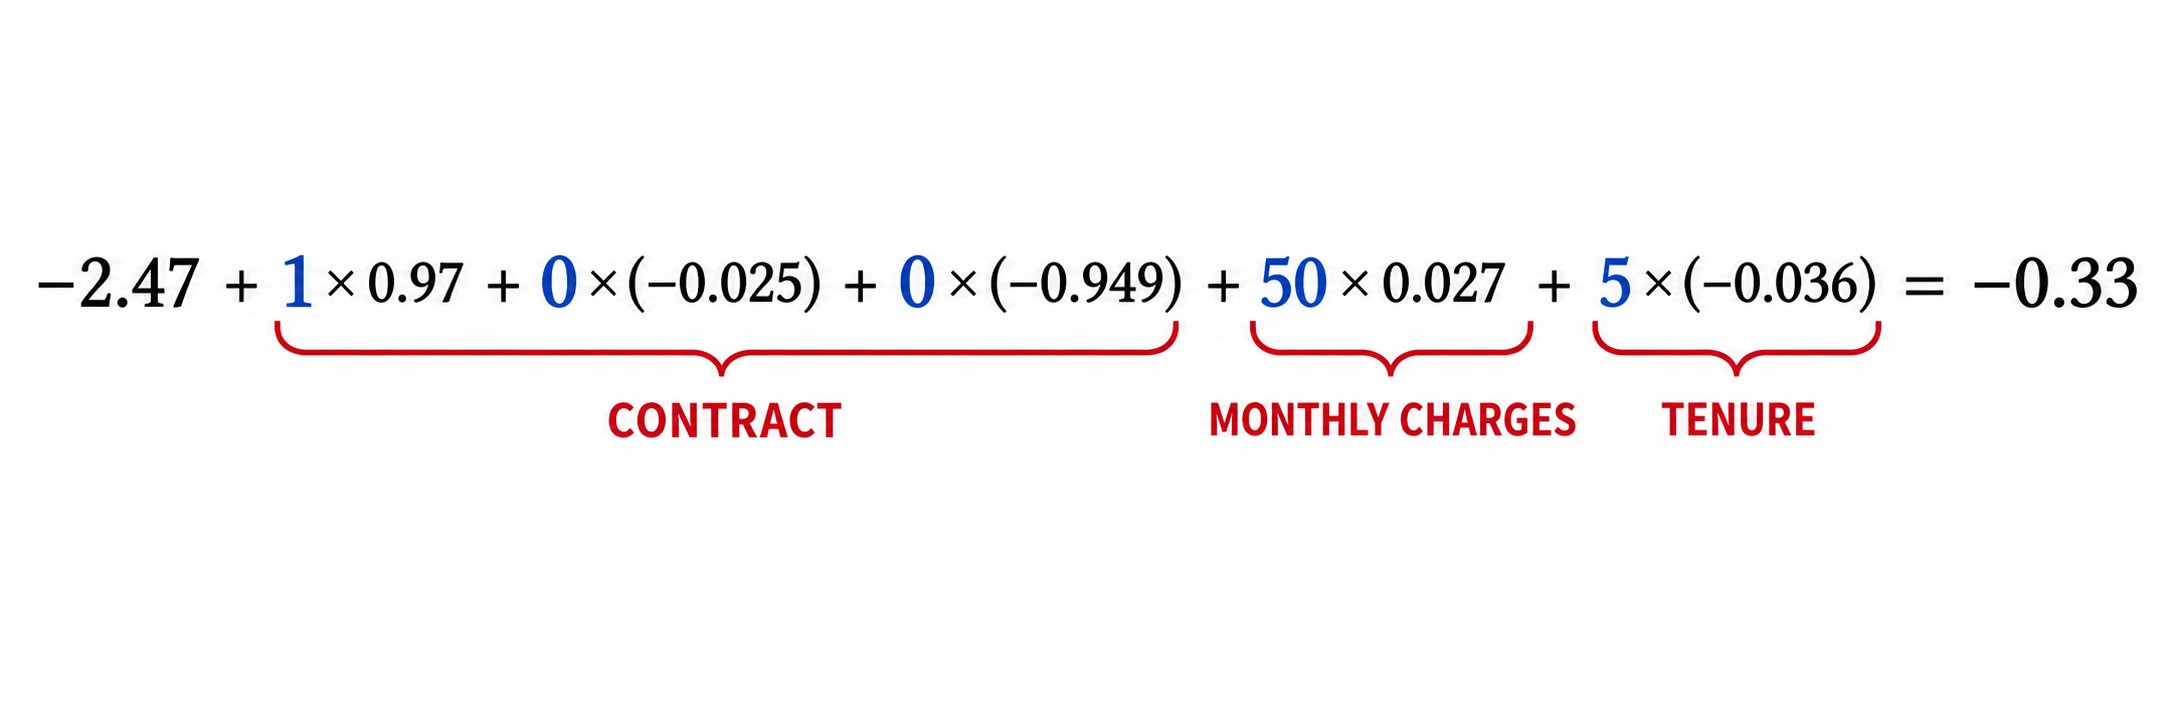

One useful observation: the sigmoid of 0 is 0.5. So if the score is positive, the customer is more likely to churn than not; if it is negative, less likely. In the example above the score was -0.33, just below the middle.

**Notes**

This video was about the interpretation of coefficients, and training a model with fewer features.

In the formula of the logistic regression model, only one of the one-hot encoded categories is multiplied by 1, and the other by 0. In this way, we only consider the appropriate category for each categorical feature.

Classes, functions, and methods:

zip(x,y) - returns a new list with elements from x joined with their corresponding elements on y

### **3.12 - Using the Model**

The model is ready. In this lesson we do the final step of the project: retrain it on the full training data (train plus validation), check it on the held-out test set, and score individual customers with it.

**Final model**

During training and tuning we kept the test set untouched. Now that we no longer need the validation set for checking the model, we can use that data for training too - more data usually means a slightly better model. That is exactly what df_full_train is for

In [791]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.churn.values

In [792]:
X_full_train

array([[0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 2.58350e+02],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        4.20000e+01, 3.16055e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.10000e+01, 4.68175e+03],
       ...,
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.80000e+01, 2.97950e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        2.00000e+00, 1.14100e+02],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        1.60000e+01, 1.11485e+03]], shape=(5634, 45))

In [793]:
model = LogisticRegression(solver='lbfgs', max_iter=2000)
model.fit(X_full_train, y_full_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Note that we fit a new DictVectorizer on the full training data as well - the encoding and the model always go together.

**Checking on the test set**

Now we take the test set, encode it with the same vectorizer, and compute the predictions:



In [794]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')

In [795]:
X_test = dv.transform(dicts_test)
X_test

array([[0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        4.10000e+01, 3.32075e+03],
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 0.00000e+00,
        6.60000e+01, 6.47185e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.20000e+01, 5.24350e+02],
       ...,
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        7.10000e+01, 3.88865e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        6.50000e+01, 5.68845e+03],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.70000e+01, 1.74350e+03]], shape=(1409, 45))

In [796]:
y_pred = model.predict_proba(X_test)[:,1]

In [797]:
churn_decision = (y_pred >= 0.5)

In [798]:
churn_decision == y_test

array([ True,  True,  True, ...,  True,  True,  True], shape=(1409,))

In [799]:
(churn_decision == y_test).mean()

np.float64(0.8112136266855926)

Accuracy on the test set is about 81.5%. On validation we had 80.3%. 

The two numbers are close, which is what we want to see: the model performs on unseen data about as well as on the data it was tuned with. A large gap between the two would be a sign of overfitting.

**Scoring one customer**

In practice we will not score a whole test set - we score customers one by one. Each customer is one row of our data, so one dictionary. Take the last customer from the test set:

In [800]:
customer = dicts_test[-1]
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 17,
 'monthlycharges': 104.2,
 'totalcharges': 1743.5}

The vectorizer expects a list of dictionaries, so we wrap the customer in a list. transform - not fit_transform, because the vectorizer is already fitted:

In [ ]:
X_small = dv.transform([customer])
model.predict_proba(X_small)[0, 1] # ou model.predict_proba(X_small)[:, 1]

np.float64(0.6386846619248786)

The model gives this customer a 60% chance of churning. Since that is above our 0.5 threshold, the decision is "churn" - and indeed, this customer actually churned in the data:

In [805]:
y_test[-1]

np.int64(1)

This is how the model would be used in a real project. A service receives the customer's data as a dictionary, encodes it with the vectorizer, and asks the model for a probability. If it is above the threshold - for example, 0.5 - the business sends this customer a promotional email with a discount, hoping to keep them.

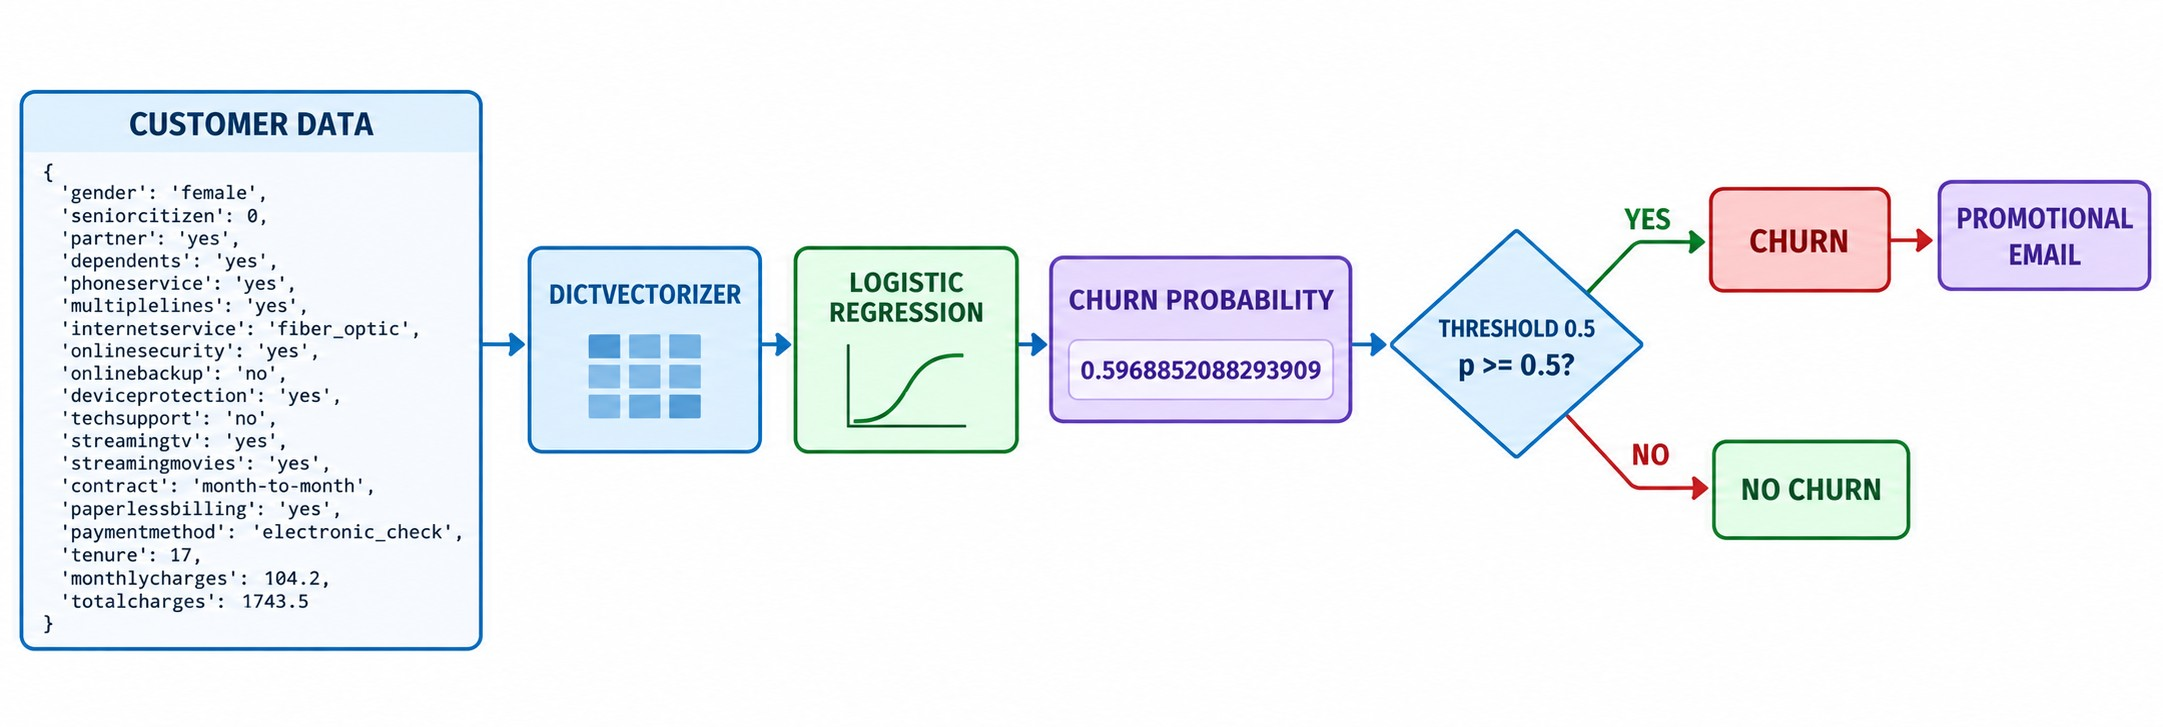

The model itself is just numbers - weights and the bias term - and the vectorizer with the list of categories. To use it outside the notebook we would need to save both to a file, which is what we cover in a later lesson.

**Notes**

We trained the logistic regression model with the full training dataset (training + validation), considering numerical and categorical features. Thus, predictions were made on the test dataset, and we evaluated the model using the accuracy metric.

In this case, the predictions of validation and test were similar, which means that the model is working well.